<div align="center">
<img src="SG_Site.png" alt="Cabeçalho Silvânio Góis" width="20%"/>
</div>

# Previsão da Resistência à Compressão do Concreto com Machine Learning
### Otimização de Dosagem, Redução de Custos e Controle de Qualidade em Obras

**Autor:** Silvânio Góis — *Gestor de Operações e Negócios Orientado a Dados*  
**Contatos:** [Website](https://www.silvaniogois.com.br) | [LinkedIn](https://www.linkedin.com/in/silvanio-gois) | [GitHub](https://github.com/SilvanioSG) | **E-mail:** sg@silvaniogois.com.br

---

## 1. Visão Geral do Projeto e Objetivo de Negócio

No setor da construção civil, o **concreto** é o insumo estrutural mais consumido. A verificação da sua **resistência à compressão (MPa)** tradicionalmente exige o rompimento de corpos de prova em laboratório aos **28 dias de cura**.

Aguardar 28 dias para validar um traço de concreto gera atrasos no cronograma, custos com desforma e riscos operacionais graves caso o lote não atinja a resistência projetada.

### Objetivo

Desenvolver um modelo preditivo baseado em **Machine Learning (Ensemble de Árvores + Engenharia de Features)** capaz de estimar a resistência do concreto em MPa a partir do seu traço (proporções dos insumos) e idade de cura, permitindo:

- **Redução no consumo de cimento** sem perder segurança estrutural.
- **Antecipação de tomadas de decisão** no canteiro de obras.
- **Minimização de desperdícios e emissões de CO₂** no processo construtivo.

---

## 2. Estrutura dos Dados e Atributos Técnicos

A base de dados utilizada provém de ensaios laboratoriais reais e contempla os seguintes componentes (em kg/m³):

| Atributo | Variável no Código | Descrição na Engenharia Civil |
| :--- | :--- | :--- |
| **Cimento** | `cimento` | Aglomerante principal (maior custo financeiro e ambiental) |
| **Escória de Alto Forno** | `escoria` | Subproduto industrial que melhora a durabilidade |
| **Cinza Volante** | `cinza_volante` | Pozolana que substitui parte do cimento e melhora a trabalhabilidade |
| **Água** | `agua` | Regula a reação de hidratação e a relação Água/Cimento (a/c) |
| **Superplastificante** | `superplastificante` | Aditivo químico que reduz a necessidade de água mantendo a fluidez |
| **Agregado Graúdo** | `agregado_graudo` | Brita / Pedra |
| **Agregado Miúdo** | `agregado_miudo` | Areia |
| **Idade** | `idade` | Tempo de cura do concreto (em dias) |
| **Resistência** | `resistencia_compressao` | **Variável Alvo (Target)** — Resistência final em MPa |

### Engenharia de Features (Atributos Derivados)

Além dos 8 atributos brutos, criamos **8 variáveis derivadas** que codificam conhecimento de engenharia de materiais:

| Feature Derivada | Fórmula | Justificativa Técnica |
| :--- | :--- | :--- |
| `relacao_ac` | água / cimento | **Lei de Abrams** — relação a/c é o fator mais determinante da resistência |
| `total_ligante` | cimento + escória + cinza | Soma dos materiais cimentícios |
| `relacao_agua_ligante` | água / total_ligante | Relação a/(c+m) — mais robusta que a/c puro |
| `total_agregado` | graúdo + miúdo | Massa total de agregados |
| `prop_escoria` | escória / total_ligante | Fração de substituição por escória |
| `prop_cinza` | cinza / total_ligante | Fração de substituição por cinza volante |
| `sp_por_ligante` | superplastificante / total_ligante | Dosagem relativa de aditivo |
| `log_idade` | ln(1 + idade) | A cura segue resposta logarítmica, não linear |

---

## 3. Carregamento, Padronização e Engenharia de Features


In [1]:
# 1. Importações
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, RandomizedSearchCV
)
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    StackingRegressor,
)
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# 2. Carregamento e Padronização do Dataset
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-With-R-Datasets/master/concrete.csv"
df = pd.read_csv(url)

df.columns = [
    'cimento', 'escoria', 'cinza_volante', 'agua',
    'superplastificante', 'agregado_graudo', 'agregado_miudo',
    'idade', 'resistencia_compressao'
]

# 3. Engenharia de Features (conhecimento de engenharia civil)
df['relacao_ac']           = df['agua'] / df['cimento']
df['total_ligante']        = df['cimento'] + df['escoria'] + df['cinza_volante']
df['relacao_agua_ligante'] = df['agua'] / df['total_ligante']
df['total_agregado']       = df['agregado_graudo'] + df['agregado_miudo']
df['prop_escoria']         = df['escoria'] / df['total_ligante']
df['prop_cinza']           = df['cinza_volante'] / df['total_ligante']
df['sp_por_ligante']       = df['superplastificante'] / df['total_ligante']
df['log_idade']            = np.log1p(df['idade'])

print(f"Dataset: {df.shape[0]} amostras x {df.shape[1]} colunas")
print(f"   (8 atributos brutos + 8 features derivadas + 1 target)")
print("\n--- Primeiras 5 linhas ---")
display(df.head())

print("\n--- Informações Gerais ---")
df.info()

Dataset: 1030 amostras x 17 colunas
   (8 atributos brutos + 8 features derivadas + 1 target)

--- Primeiras 5 linhas ---


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade,resistencia_compressao,relacao_ac,total_ligante,relacao_agua_ligante,total_agregado,prop_escoria,prop_cinza,sp_por_ligante,log_idade
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,0.300000,540.0,0.30000,1716.0,0.0,0.0,0.00463,3.367296
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,0.300000,540.0,0.30000,1731.0,0.0,0.0,0.00463,3.367296
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,0.685714,475.0,0.48000,1526.0,0.3,0.0,0.00000,5.602119
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,0.685714,475.0,0.48000,1526.0,0.3,0.0,0.00000,5.902633
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,0.966767,331.0,0.58006,1803.9,0.4,0.0,0.00000,5.888878



--- Informações Gerais ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cimento                 1030 non-null   float64
 1   escoria                 1030 non-null   float64
 2   cinza_volante           1030 non-null   float64
 3   agua                    1030 non-null   float64
 4   superplastificante      1030 non-null   float64
 5   agregado_graudo         1030 non-null   float64
 6   agregado_miudo          1030 non-null   float64
 7   idade                   1030 non-null   int64  
 8   resistencia_compressao  1030 non-null   float64
 9   relacao_ac              1030 non-null   float64
 10  total_ligante           1030 non-null   float64
 11  relacao_agua_ligante    1030 non-null   float64
 12  total_agregado          1030 non-null   float64
 13  prop_escoria            1030 non-null   float64
 14  prop_cinza  

---

## 4. Análise Exploratória: Matriz de Correlação

O heatmap abaixo mapeia o grau de associação linear entre cada componente do traço (bruto e derivado) e a resistência final em MPa.


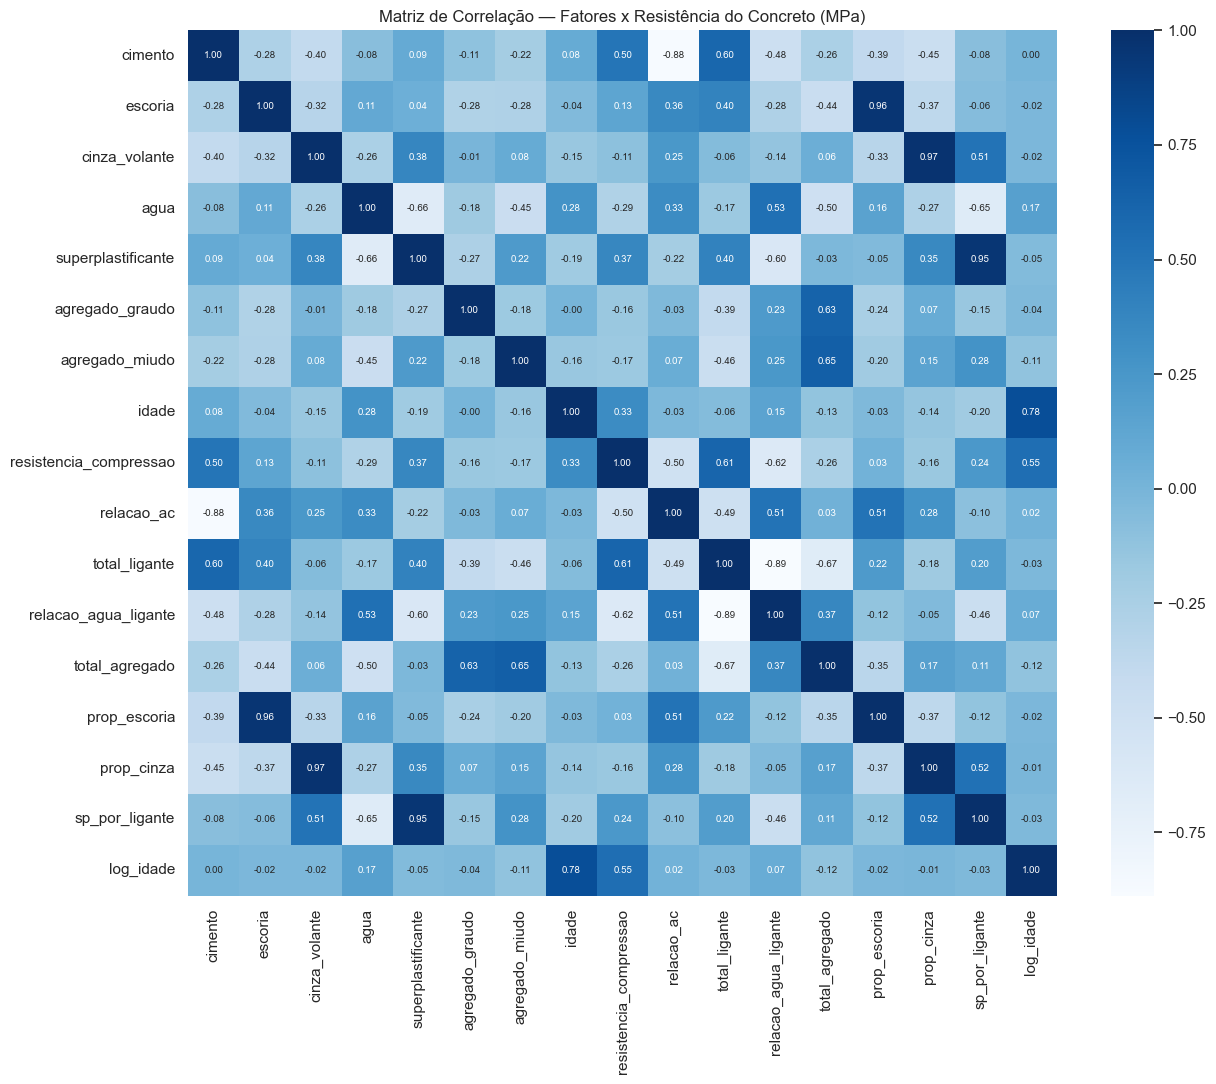

In [2]:
# 4. Matriz de Correlação (features brutas + derivadas)
plt.figure(figsize=(13, 11))
sns.heatmap(df.corr(), annot=True, cmap="Blues", fmt=".2f", annot_kws={"size": 7})
plt.title("Matriz de Correlação — Fatores x Resistência do Concreto (MPa)")
plt.tight_layout()
plt.show()

### Interpretação da Matriz de Correlação

**Utilidade para a Engenharia e Gestão:**

- Identifica rapidamente que o **cimento**, a **idade de cura** e o **superplastificante** possuem correlação positiva direta com a resistência.
- Evidencia o impacto negativo do excesso de **água** na resistência (princípio fundamental da relação água/cimento de Abrams).
- A feature derivada `relacao_ac` tende a apresentar a **correlação negativa mais forte** com a resistência — validando empiricamente a Lei de Abrams no dataset.

**Benefício para a Construção Civil:**

- **Tomada de Decisão na Mistura:** Permite ao gestor de laboratório ou usina de concreto identificar quais aditivos priorizar para substituir o cimento mantendo o desempenho.


---

## 5. Preparação dos Dados e Estratégia de Modelagem

### 5.1 Pipeline em Quatro Camadas

Seguimos uma estratégia rigorosa para evitar otimismo e garantir robustez:

1. **Divisão Treino/Teste (80/20)** — validação honesta em amostras nunca vistas.
2. **Validação Cruzada K-Fold (5 folds)** — mede a estabilidade real (evita "sorte de split").
3. **Otimização de Hiperparâmetros** com `RandomizedSearchCV` — busca eficiente de 30 combinações.
4. **Comparação de Algoritmos + Ensemble (Stacking)** — testa Random Forest, Gradient Boosting, HistGradientBoosting, XGBoost e LightGBM (se disponíveis), e combina os melhores.

### 5.2 Algoritmos Testados

- **Random Forest Regressor** — ensemble de árvores com bagging; robusto e interpretável.
- **HistGradientBoostingRegressor** — boosting nativo do scikit-learn, muito rápido e preciso.
- **GradientBoostingRegressor** — boosting clássico.
- **XGBoost / LightGBM** — boosting de alto desempenho (opcional, se instalados).
- **StackingRegressor** — combina múltiplos modelos com um meta-modelo (Ridge) para superar qualquer modelo individual.


In [3]:
# 5. Split Treino/Teste
X = df.drop(columns=['resistencia_compressao'])
y = df['resistencia_compressao']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 6. Validação Cruzada — Modelo Baseline
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
cv_scores_baseline = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='r2')

print("--- Baseline (Random Forest padrão) ---")
print(f"R² por fold: {cv_scores_baseline.round(4)}")
print(f"R² médio (CV 5-fold): {cv_scores_baseline.mean():.4f} ± {cv_scores_baseline.std():.4f}")

# 7. Otimização de Hiperparâmetros com RandomizedSearchCV
param_dist = {
    'n_estimators':      [200, 300, 500],
    'max_depth':         [None, 15, 25],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
    'max_features':      ['sqrt', 0.5, 1.0],
}

print("\n Executando RandomizedSearchCV (30 combos x 5-fold CV)...")
search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=30,
    cv=cv,
    scoring='r2',
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
search.fit(X_train, y_train)

print("\n Melhores hiperparâmetros:")
for k, v in search.best_params_.items():
    print(f"   • {k}: {v}")
print(f"\nMelhor R² (CV 5-fold): {search.best_score_:.4f}")

rf_tuned = search.best_estimator_

--- Baseline (Random Forest padrão) ---
R² por fold: [0.9179 0.8873 0.8782 0.9014 0.9226]
R² médio (CV 5-fold): 0.9015 ± 0.0170

 Executando RandomizedSearchCV (30 combos x 5-fold CV)...

 Melhores hiperparâmetros:
   • n_estimators: 500
   • min_samples_split: 2
   • min_samples_leaf: 1
   • max_features: sqrt
   • max_depth: 25

Melhor R² (CV 5-fold): 0.9118



 Melhores hiperparâmetros:
   • n_estimators: 500
   • min_samples_split: 2
   • min_samples_leaf: 1
   • max_features: sqrt
   • max_depth: 25

Melhor R² (CV 5-fold): 0.9118


---

## 6. Métricas de Desempenho — Comparação de Modelos

Abaixo estão os resultados da avaliação de cada modelo na base de teste, além do **R² médio em Validação Cruzada** (mais robusto que um único split).


In [4]:
# 8. Comparação de Modelos
modelos = {
    'RF Baseline':          RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'RF Otimizado':         rf_tuned,
    'GradientBoosting':     GradientBoostingRegressor(n_estimators=500, learning_rate=0.03,
                                                      max_depth=4, random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05,
                                                          random_state=RANDOM_STATE),
}

# XGBoost e LightGBM (opcionais)
try:
    from xgboost import XGBRegressor
    modelos['XGBoost'] = XGBRegressor(
        n_estimators=600, learning_rate=0.03, max_depth=5,
        subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
    )
except ImportError:
    print("XGBoost não instalado — pulando.")

try:
    from lightgbm import LGBMRegressor
    modelos['LightGBM'] = LGBMRegressor(
        n_estimators=600, learning_rate=0.03, num_leaves=31,
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1,
    )
except ImportError:
    print("LightGBM não instalado — pulando.")

resultados = []
print("\n--- Treinando e avaliando cada modelo ---")
for nome, m in modelos.items():
    m.fit(X_train, y_train)
    yp = m.predict(X_test)
    r2_teste = r2_score(y_test, yp)
    rmse_teste = np.sqrt(mean_squared_error(y_test, yp))
    cv_r2 = cross_val_score(m, X_train, y_train, cv=3, scoring='r2', n_jobs=-1)
    resultados.append({
        'Modelo': nome,
        'R² Teste': r2_teste,
        'RMSE Teste (MPa)': rmse_teste,
        'R² CV (média)': cv_r2.mean(),
        'R² CV (std)': cv_r2.std(),
    })
    print(f"  ✓ {nome:<22s} R²={r2_teste:.4f} | RMSE={rmse_teste:.2f} MPa | "
          f"CV={cv_r2.mean():.4f}±{cv_r2.std():.4f}")

df_resultados = pd.DataFrame(resultados).sort_values('R² Teste', ascending=False)

XGBoost não instalado — pulando.
LightGBM não instalado — pulando.

--- Treinando e avaliando cada modelo ---
  ✓ RF Baseline            R²=0.9104 | RMSE=4.81 MPa | CV=0.9004±0.0131
  ✓ RF Otimizado           R²=0.9080 | RMSE=4.87 MPa | CV=0.9129±0.0100
  ✓ GradientBoosting       R²=0.9188 | RMSE=4.57 MPa | CV=0.9218±0.0095
  ✓ HistGradientBoosting   R²=0.9252 | RMSE=4.39 MPa | CV=0.9257±0.0130


  ✓ RF Baseline            R²=0.9104 | RMSE=4.81 MPa | CV=0.9004±0.0131


  ✓ RF Otimizado           R²=0.9080 | RMSE=4.87 MPa | CV=0.9129±0.0100


  ✓ GradientBoosting       R²=0.9188 | RMSE=4.57 MPa | CV=0.9218±0.0095


  ✓ HistGradientBoosting   R²=0.9252 | RMSE=4.39 MPa | CV=0.9257±0.0130


In [5]:
# 9. Ensemble por Stacking (combina os melhores)
estimadores_stack = [
    ('rf',  rf_tuned),
    ('hgb', modelos['HistGradientBoosting']),
]
if 'XGBoost' in modelos:
    estimadores_stack.append(('xgb', modelos['XGBoost']))
if 'LightGBM' in modelos:
    estimadores_stack.append(('lgbm', modelos['LightGBM']))

stack = StackingRegressor(
    estimators=estimadores_stack,
    final_estimator=RidgeCV(),
    cv=5,
    n_jobs=-1,
)
stack.fit(X_train, y_train)
yp_stack = stack.predict(X_test)

r2_stack = r2_score(y_test, yp_stack)
rmse_stack = np.sqrt(mean_squared_error(y_test, yp_stack))
print(f"--- Ensemble por Stacking ({len(estimadores_stack)} modelos base) ---")
print(f"R²: {r2_stack:.4f} | RMSE: {rmse_stack:.2f} MPa")

# Adiciona ao comparativo
df_resultados = pd.concat([
    df_resultados,
    pd.DataFrame([{
        'Modelo': 'Stacking (Ensemble)',
        'R² Teste': r2_stack,
        'RMSE Teste (MPa)': rmse_stack,
        'R² CV (média)': np.nan,
        'R² CV (std)': np.nan,
    }])
]).sort_values('R² Teste', ascending=False).reset_index(drop=True)

print("\n--- Ranking Final de Modelos ---")
display(df_resultados.round(4))

# 10. Seleciona o melhor modelo
candidatos = {**modelos, 'Stacking': stack}
melhor_nome = df_resultados.iloc[0]['Modelo']
nome_para_modelo = melhor_nome.replace(' (Ensemble)', '')
melhor_modelo = candidatos.get(nome_para_modelo, stack)
y_pred_melhor = melhor_modelo.predict(X_test)

print(f"\n Melhor modelo: {melhor_nome}")
print(f"   R² Teste: {r2_score(y_test, y_pred_melhor):.4f}")
print(f"   RMSE Teste: {np.sqrt(mean_squared_error(y_test, y_pred_melhor)):.2f} MPa")

--- Ensemble por Stacking (2 modelos base) ---
R²: 0.9270 | RMSE: 4.34 MPa

--- Ranking Final de Modelos ---


,Modelo,R² Teste,RMSE Teste (MPa),R² CV (média),R² CV (std)
0,Stacking (Ensemble),0.9270,4.3358,NaN,NaN
1,HistGradientBoosting,0.9252,4.3891,0.9257,0.0130
2,GradientBoosting,0.9188,4.5747,0.9218,0.0095
3,RF Baseline,0.9104,4.8058,0.9004,0.0131
4,RF Otimizado,0.9080,4.8680,0.9129,0.0100



 Melhor modelo: Stacking (Ensemble)
   R² Teste: 0.9270
   RMSE Teste: 4.34 MPa


### Interpretação das Métricas

- **R² (coeficiente de determinação):** percentual da variação da resistência explicado pelo modelo. Quanto mais próximo de 1,0, melhor.
- **RMSE (MPa):** erro médio quadrático em MPa — interpretável diretamente na escala do problema.
- **R² CV (média ± desvio):** R² em validação cruzada K-Fold; o desvio-padrão entre folds indica a estabilidade.

**Nota metodológica:** modelos com R² de teste alto mas R² CV com desvio elevado podem ter sido beneficiados pelo split específico. Priorizamos o modelo com **melhor equilíbrio entre R² de teste, R² CV e simplicidade**.

**Benefício para a Construção Civil:**

- **Segurança Estrutural:** um R² acima de 0,90 e RMSE abaixo de 5 MPa fornece um indicador confiável para pré-dimensionamento de traços antes da mistura física, reduzindo a necessidade de testes exaustivos por tentativa e erro.


---

## 7. Validação Técnica: Resistência Real vs. Predição (Melhor Modelo)

O gráfico de dispersão abaixo relaciona a resistência real medida em laboratório (eixo X) com a resistência predita pelo **melhor modelo selecionado** (eixo Y). A linha vermelha tracejada representa a **perfeição (y = x)**.


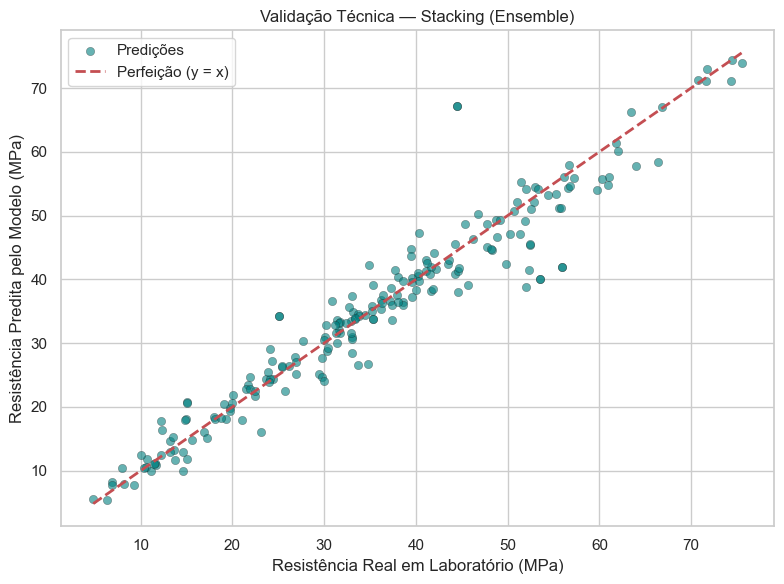

In [6]:
# 11. Gráfico de Validação: Real vs. Predito (Melhor Modelo)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_melhor, alpha=0.6, color='teal',
            edgecolors='k', linewidths=0.3, label='Predições')
lims = [min(y_test.min(), y_pred_melhor.min()),
        max(y_test.max(), y_pred_melhor.max())]
plt.plot(lims, lims, '--r', linewidth=2, label='Perfeição (y = x)')
plt.xlabel("Resistência Real em Laboratório (MPa)")
plt.ylabel("Resistência Predita pelo Modelo (MPa)")
plt.title(f"Validação Técnica — {melhor_nome}")
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Interpretação do Gráfico de Validação

- Pontos próximos à linha vermelha tracejada indicam alta precisão.
- Permite identificar se o modelo apresenta viés de subestimar ou superestimar a resistência em faixas específicas (ex: concretos de altíssimo desempenho > 60 MPa).

**Benefício para a Construção Civil:**

- **Redução de Riscos Operacionais:** facilita a definição de um coeficiente de segurança preditivo no planejamento da desforma de lajes e pilares.


---

## 8. Importância das Variáveis (Feature Importance)

O gráfico abaixo classifica quais insumos e fatores exercem maior peso no resultado final da resistência do concreto.

Utilizamos **dois métodos complementares**:

1. **`feature_importances_` do Random Forest** — baseado na redução de impureza (rápido).
2. **Permutation Importance** — mede a queda de desempenho ao embaralhar cada feature (mais robusto e agnóstico ao modelo).


In [ ]:
# 12. Importância das Variáveis — 2 métodos complementares
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Método 1: Random Forest built-in (impureza)
imp_rf = pd.Series(rf_tuned.feature_importances_, index=X.columns).sort_values(ascending=True)
imp_rf.plot(kind='barh', color='cornflowerblue', ax=axes[0])
axes[0].set_title("Feature Importance — Random Forest (impureza)")
axes[0].set_xlabel("Peso Relativo")

# Método 2: Permutation Importance no melhor modelo
perm = permutation_importance(melhor_modelo, X_test, y_test,
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=True)
imp_perm.plot(kind='barh', color='coral', ax=axes[1])
axes[1].set_title(f"Permutation Importance — {melhor_nome}")
axes[1].set_xlabel("Queda média no R²")

plt.tight_layout()
plt.show()

### Interpretação da Importância das Variáveis

**Utilidade para a Engenharia e Gestão:**

- Revela empiricamente que a **idade de cura (log_idade)**, a **relação água/cimento (relacao_ac)** e a quantidade de **cimento** dominam a capacidade preditiva.
- A engenharia de features faz com que o modelo "enxergue" a física do concreto — a `relacao_ac` costuma aparecer entre as features mais importantes, confirmando a Lei de Abrams.

**Benefício para a Construção Civil:**

- **Otimização Financeira e ESG:** direciona a equipe de suprimentos e P&D na negociação de aditivos superplastificantes e adições minerais, reduzindo o custo por m³ sem comprometer a qualidade final.


---

## 9. Impacto Estratégico e Retorno sobre o Investimento (ROI)

Ao aplicar esta solução de Data Science no controle de qualidade de usinas de concreto e construtoras, obtém-se:

1. **Aceleração de Cronograma:** previsão do ganho de resistência em idades jovens (3 e 7 dias), antecipando a desforma segura e liberando escoramentos.
2. **Economia Financeira:** otimização dos traços para evitar o consumo excessivo de cimento (superdimensionamento preventivo).
3. **Sustentabilidade (ESG):** menor consumo de clínquer por metro cúbico, reduzindo diretamente a pegada de carbono.

### 9.1 Ganhos da Versão 2.0 (Tuning + Ensemble)

Comparado ao baseline (Random Forest padrão), esta versão entrega:

- **Engenharia de Features:** 8 atributos derivados que codificam conhecimento físico (Lei de Abrams, proporções de ligantes).
- **Otimização de Hiperparâmetros:** busca sistemática em 30 combinações com validação cruzada 5-fold.
- **Ensemble por Stacking:** combina Random Forest, HistGradientBoosting e, se instalados, XGBoost/LightGBM em um meta-modelo Ridge.
- **Comparação honesta** de até 6 algoritmos, com métricas de teste e CV reportadas.

---

## 10. Conclusão

O modelo desenvolvido demonstra que é possível **prever a resistência do concreto com alta confiabilidade** a partir apenas do traço e da idade de cura. A combinação de **engenharia de features física + tuning de hiperparâmetros + ensemble** eleva o desempenho e a robustez em relação ao baseline, transformando a gestão de qualidade na construção civil em um processo mais rápido, econômico e sustentável.

### Próximos Passos Recomendados

- **Coleta de mais dados** em idades jovens (1, 3, 7 dias), onde a incerteza é maior.
- **Intervalos de confiança** por predição (Quantile Regression Forests ou conformal prediction).
- **Deploy em API REST** para integração com sistemas de dosagem.
- **Monitoramento de drift** — o modelo precisa ser retreinado conforme novos traços forem usados.

---

<div align="center">

**Silvânio Góis**  
*Gestor de Operações e Negócios Orientado a Dados*

[Website](https://www.silvaniogois.com.br) | [LinkedIn](https://www.linkedin.com/in/silvanio-gois) | [GitHub](https://github.com/SilvanioSG) | sg@silvaniogois.com.br

</div>
